# 05 · Milestone 2 results

Every model was tuned and tested on **5 different site-owner splits** (seeds 42, 0, 1, 2, 3). We report:
- **mean ± sd** over those splits
- for the reference split (seed 42), a **95% confidence interval** that resamples whole site owners (`phishguard.stats.owner_bootstrap_ci`)

Each notebook saved its results to `results/m2/`; this notebook only reads them.

In [1]:
import itertools
import matplotlib.pyplot as plt
import pandas as pd

from phishguard.data import load_clean, TARGET
from phishguard.evaluate import load_results, precision_at_base_rate
from phishguard.experiment import load_predictions, load_record
from phishguard.stats import mcnemar

results = load_results("m2")
cols = ["model", "accuracy", "accuracy_sd", "ref_accuracy", "ref_ci_low", "ref_ci_high", "ref_errors",
        "f1", "roc_auc", "pr_auc", "mcc", "tpr_at_fpr_1pct"]
table = results[cols].copy()
for c in ["accuracy", "accuracy_sd", "ref_accuracy", "ref_ci_low", "ref_ci_high", "f1", "tpr_at_fpr_1pct"]:
    table[c] = (table[c] * 100).round(3)
print(table.to_string(index=False))

                               model  accuracy  accuracy_sd  ref_accuracy  ref_ci_low  ref_ci_high  ref_errors      f1  roc_auc   pr_auc      mcc  tpr_at_fpr_1pct
         Random Forest (all columns)   100.000        0.000       100.000     100.000      100.000           0 100.000 1.000000 1.000000 1.000000          100.000
               XGBoost (all columns)   100.000        0.000       100.000     100.000      100.000           0 100.000 1.000000 1.000000 1.000000          100.000
                LogReg (all columns)    99.988        0.004        99.991      99.980      100.000           3  99.986 0.999989 0.999988 0.999754           99.995
Average: n-gram + XGBoost (URL only)    99.699        0.031        99.747      99.685       99.799          89  99.643 0.998550 0.998798 0.993840           99.509
        Char n-gram LogReg (raw URL)    99.686        0.047        99.747      99.691       99.801          89  99.628 0.998554 0.998819 0.993582           99.512
              XGBoost 

Columns: `accuracy` ± `accuracy_sd` = mean ± sd over 5 splits (%). `ref_*` = the seed-42 split, its 95% CI and number of errors. `tpr_at_fpr_1pct` = share of phishing caught while flagging at most 1% of legitimate URLs.

## Are the differences real?

**McNemar's test** on the seed-42 test set compares each pair of URL-only models. It only looks at URLs where the two models disagree. A **p-value** above 0.05 means the difference could easily be chance.

In [2]:
df = load_clean()
url_models = [m for m in results["model"] if "all columns" not in m]
preds = {m: load_predictions("m2", m) for m in url_models}
truth = df[TARGET].loc[preds[url_models[0]]["test_idx"]].to_numpy()
correct = {m: (p["test_prob"] >= p["threshold"]) == truth for m, p in preds.items()}

rows = [{"model A": a, "model B": b, **mcnemar(correct[a], correct[b])}
        for a, b in itertools.combinations(url_models, 2)]
pd.DataFrame(rows).round(4)

,model A,model B,only_a_right,only_b_right,p_value
0,Average: n-gram + XGBoost (URL only),Char n-gram LogReg (raw URL),17,17,1.0000
1,Average: n-gram + XGBoost (URL only),XGBoost (URL features),30,8,0.0005
2,Average: n-gram + XGBoost (URL only),Random Forest (URL features),26,9,0.0060
3,Char n-gram LogReg (raw URL),XGBoost (URL features),38,16,0.0038
4,Char n-gram LogReg (raw URL),Random Forest (URL features),34,17,0.0241
5,XGBoost (URL features),Random Forest (URL features),7,12,0.3593


## Compared with published work

The published numbers come from **different splits and protocols** (see `docs/references.md`), so they are context, not a head-to-head comparison. Our bars show mean ± sd over 5 splits.

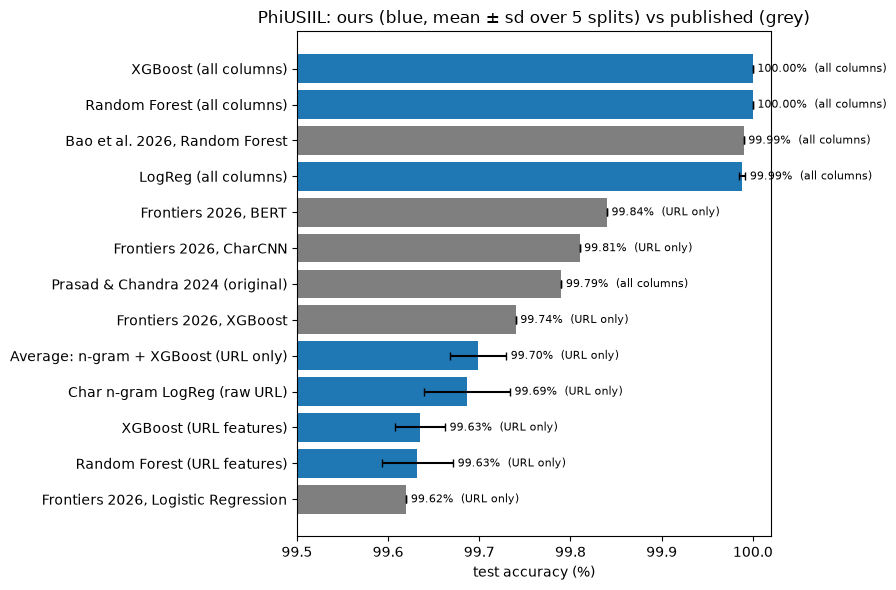

In [3]:
published = pd.DataFrame([
    ("Prasad & Chandra 2024 (original)", "all columns", 99.79),
    ("Bao et al. 2026, Random Forest", "all columns", 99.99),
    ("Frontiers 2026, Logistic Regression", "URL only", 99.62),
    ("Frontiers 2026, XGBoost", "URL only", 99.74),
    ("Frontiers 2026, CharCNN", "URL only", 99.81),
    ("Frontiers 2026, BERT", "URL only", 99.84),
], columns=["model", "input", "accuracy"]).assign(sd=0.0, source="published")

ours = results.assign(
    input=results["features"].map(lambda f: "all columns" if f == "all provided columns" else "URL only"),
    accuracy=results["accuracy"] * 100, sd=results["accuracy_sd"] * 100, source="ours",
)[["model", "input", "accuracy", "sd", "source"]]
both = pd.concat([ours, published]).sort_values("accuracy").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(both["model"], both["accuracy"], xerr=both["sd"], capsize=3,
        color=both["source"].map({"ours": "tab:blue", "published": "tab:gray"}))
ax.set_xlim(99.5, 100.02)
ax.set_xlabel("test accuracy (%)")
ax.set_title("PhiUSIIL: ours (blue, mean ± sd over 5 splits) vs published (grey)")
for i, row in both.iterrows():
    ax.text(row["accuracy"] + row["sd"] + 0.005, i, f"{row['accuracy']:.2f}%  ({row['input']})", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## What would these models do in real traffic?

In PhiUSIIL, 42% of URLs are phishing. In real browsing, far fewer are, perhaps 1% or less. Precision depends heavily on that **base rate**:

precision = recall·p / (recall·p + false-alarm-rate·(1 − p))

Here is the best URL-only model's seed-42 recall and false-alarm rate, carried over to lower phishing rates:

In [4]:
best_url = results[~results["features"].eq("all provided columns")].iloc[0]
ref = load_record("m2", best_url["model"])["reference"]["test"]
recall, fpr = ref["recall"], ref["fp"] / (ref["fp"] + ref["tn"])
print(f"{best_url['model']}: recall {recall:.2%}, false-alarm rate {fpr:.3%}")
pd.Series({f"{p:.1%} phishing": precision_at_base_rate(recall, fpr, p) for p in [0.42, 0.10, 0.01, 0.001]},
          name="precision").map("{:.1%}".format)

Average: n-gram + XGBoost (URL only): recall 99.48%, false-alarm rate 0.054%


42.0% phishing    99.9%
10.0% phishing    99.5%
1.0% phishing     94.9%
0.1% phishing     64.7%
Name: precision, dtype: str

## What we can say
1. **Target reached.** On all provided columns, every model scores ≥ 99.99% on every split. The models are indistinguishable from each other and from perfect, which reproduces the published results.
2. **URL only, which is what the app needs: about 99.7%.** That's comparable with published URL-only results, which come from different splits. Check the McNemar table before ranking the URL-only models: several differences are within noise.
3. **What's left:** nearly all remaining errors are phishing sites shaped like a bare `https://www.<domain>` homepage, the shape *every* legitimate URL in the dataset has.
4. **Real traffic:** at realistic phishing rates, even ~99.7% accuracy means a noticeable share of alarms are false. That's why we also report PR-AUC and the catch rate at 1% false alarms.
5. **Open question for Milestone 3:** the models lean heavily on how a URL *starts* and on a few provided columns. Is that phishing knowledge, or how the dataset was collected?